# Where sunlight goes, advanced: the diurnal course of surface temperature

[![Open in Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/radiation_balance_pro_en.ipynb)

**OpenSkyLab · notebook for the visual** [Where radiation goes](https://openskylab.space/edu_viz_radiation_balance.html) · [česká verze](radiation_balance_pro_cs.ipynb)

The advanced version of the radiation balance notebook. Instead of an equilibrium in one hour you heat and cool the surface hour by hour under several days of real weather. Evaporation and heat flow into the ground join absorbed and emitted radiation, so you see why a forest is cooler than a field at noon and why a town stays warm at night.

**Goal:** build solar and longwave radiation from real weather, compute the diurnal course of surface temperature with a force-restore model, split net radiation into sensible heat, evaporation and ground heat flux, and explain the roles of albedo, water availability and thermal inertia.

**Data:** Surface albedo from the Sentinel-2 L2A scene `S2B_33UVR_20240721_0_L2A` (21 July 2024, near Roztoky) and ESA WorldCover 2021 classes; hourly weather for Prague from Open-Meteo (last 92 days; the days around the sunniest one are simulated). About 5 MB is downloaded. The surface properties (water availability, thermal inertia) are indicative and the model is simplified: the results show relationships, they are not a forecast of the real temperature.

**Tasks:** five. Write your answers in the *Your answer* cells below the tasks. Lines marked `# ◀ parameter` are meant to be changed; run the cell again with Shift + Enter.

**Time:** about 60 min. You need a Google account (Colab); nothing is installed on your computer. Run the cells in order from top to bottom.

## 1. Setup and surface albedo

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import time, requests, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.warp import reproject, Resampling
from pyproj import Transformer
warnings.filterwarnings("ignore")

STAC = "https://earth-search.aws.element84.com/v1/collections/sentinel-2-l2a/items/"
WORLDCOVER = "https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/ESA_WorldCover_10m_2021_v200_N48E012_Map.tif"
BANDS = ["coastal", "blue", "green", "red", "rededge1", "rededge2", "rededge3", "nir", "nir08", "swir16", "swir22"]

def read_on_grid(url, grid, resampling=Resampling.bilinear, dtype=np.float32):
    """Read a cloud raster and resample it to grid = (transform, crs, height, width)."""
    tr, crs, ny, nx = grid
    out = np.zeros((ny, nx), dtype)
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open("/vsicurl/" + url) as src:
            reproject(rasterio.band(src, 1), out, dst_transform=tr, dst_crs=crs, resampling=resampling)
    return out

def s2_window(item_id, lon, lat, half):
    """Reflectance of all Sentinel-2 L2A bands in a square around a point (10 m grid in the tile's UTM)."""
    item = requests.get(STAC + item_id, timeout=60).json()
    epsg = item["properties"]["proj:epsg"] if "proj:epsg" in item["properties"] else int(item["properties"]["proj:code"].split(":")[1])
    x, y = Transformer.from_crs(4326, epsg, always_xy=True).transform(lon, lat)
    n = int(2 * half / 10)
    grid = (rasterio.transform.from_origin(x - half, y + half, 10, 10), f"EPSG:{epsg}", n, n)
    # since processing baseline 04.00 (2022) DN carry a +1000 offset; Earth Search has already removed it for newer items
    p = item["properties"]
    offset = -1000 if float(p.get("s2:processing_baseline", "0")) >= 4 and not p.get("earthsearch:boa_offset_applied", False) else 0
    refl = {b: (read_on_grid(item["assets"][b]["href"], grid) + offset) / 10000 for b in BANDS}
    scl = read_on_grid(item["assets"]["scl"]["href"], grid, Resampling.nearest, np.uint8)
    wl = {b: item["assets"][b]["eo:bands"][0]["center_wavelength"] for b in BANDS}
    return refl, scl, wl, grid, item

def open_meteo(params, tries=6):
    """Query Open-Meteo; retry on errors or when the daily limit is exceeded."""
    for i in range(tries):
        try:
            r = requests.get("https://api.open-meteo.com/v1/forecast", params=params, timeout=60)
            if r.ok:
                return r.json()
            reason = r.json().get("reason", r.status_code)
        except requests.RequestException as e:
            reason = type(e).__name__
        print("Open-Meteo:", reason, "– retrying"); time.sleep(5 * (i + 1))
    raise RuntimeError("Open-Meteo is not responding, run the cell again in a while.")

We compute the albedo of four surfaces as in the basic version (Liang 2001, Sentinel-2 bands). We leave water out: water mixes and stores heat at depth, which a single-layer surface model cannot describe.

In [3]:
refl, scl, wl, grid, item = s2_window("S2B_33UVR_20240721_0_L2A", 14.375, 50.145, 1500)
wc = read_on_grid(WORLDCOVER, grid, Resampling.nearest, np.uint8)
clear = np.isin(scl, [4, 5, 6])
classes = {10: "forest", 30: "meadow", 40: "field", 50: "built-up"}
albedo = {}
for code, name in classes.items():
    m = clear & (wc == code)
    med = {b: float(np.median(refl[b][m])) for b in ["blue", "red", "nir", "swir16", "swir22"]}
    albedo[name] = 0.356 * med["blue"] + 0.130 * med["red"] + 0.373 * med["nir"] + 0.085 * med["swir16"] + 0.072 * med["swir22"] - 0.0018
print({k: round(v, 3) for k, v in albedo.items()})

{'forest': 0.155, 'meadow': 0.172, 'field': 0.143, 'built-up': 0.155}


## 2. Real weather as input

From Open-Meteo we take hourly global radiation, temperature, dew point, wind, cloud cover and pressure. Longwave sky radiation L↓ is computed from the clear-sky emissivity (Brutsaert 1975) and the cloud cover c is added in the form of Crawford and Duchon (1999): ε = ε_clear · (1 − c) + c. The cloud cover comes from the weather model here, not from measurements.

sunniest day 2026-08-24 (22.3 MJ/m²), simulation 2026-08-22 00:00:00 to 2026-08-25 23:00:00 UTC


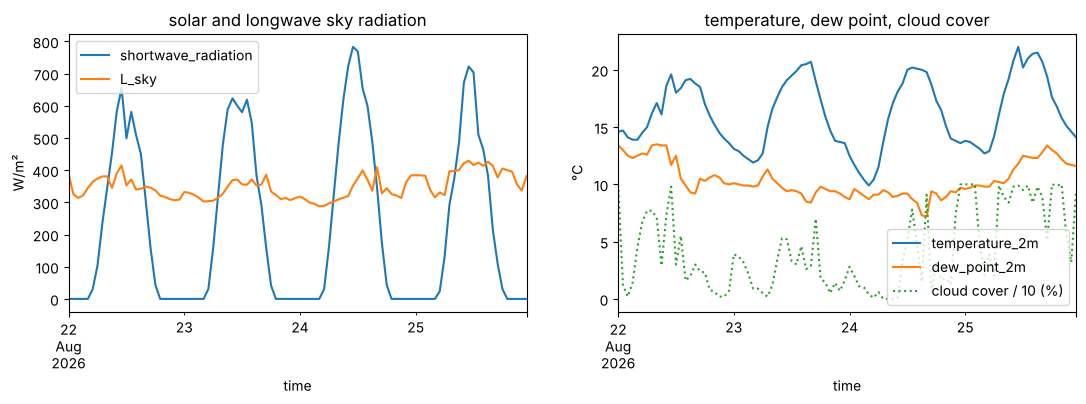

In [4]:
LAT, LON = 50.08, 14.42                     # ◀ parameter: place for the weather (Prague)
w = open_meteo({"latitude": LAT, "longitude": LON, "past_days": 92, "forecast_days": 1, "wind_speed_unit": "ms", "timezone": "UTC",
                "hourly": "shortwave_radiation,temperature_2m,dew_point_2m,wind_speed_10m,cloud_cover,surface_pressure"})
met = pd.DataFrame(w["hourly"]).assign(time=lambda d: pd.to_datetime(d.time)).set_index("time").dropna()
daily = met.shortwave_radiation.resample("D").sum() * 3600 / 1e6            # MJ/m² per day
best = daily.idxmax()
N_DAYS = 4                                   # ◀ parameter: how many days to simulate (the sunniest day is in the middle)
start = best - pd.Timedelta(days=N_DAYS // 2)
F = met.loc[start: start + pd.Timedelta(days=N_DAYS) - pd.Timedelta(hours=1)].copy()
SIGMA = 5.670374e-8
F["Ta"] = F.temperature_2m + 273.15
F["e_a"] = 6.112 * np.exp(17.62 * F.dew_point_2m / (243.12 + F.dew_point_2m))          # hPa
eps_clear = 1.24 * (F.e_a / F.Ta) ** (1 / 7)                                          # Brutsaert 1975
F["L_sky"] = (eps_clear * (1 - F.cloud_cover / 100) + F.cloud_cover / 100) * SIGMA * F.Ta ** 4
F["q_a"] = 0.622 * F.e_a / F.surface_pressure
print(f"sunniest day {best.date()} ({daily.max():.1f} MJ/m²), simulation {F.index[0]} to {F.index[-1]} UTC")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
F[["shortwave_radiation", "L_sky"]].plot(ax=ax[0]); ax[0].set(ylabel="W/m²", title="solar and longwave sky radiation")
F[["temperature_2m", "dew_point_2m"]].plot(ax=ax[1]); (F.cloud_cover / 10).plot(ax=ax[1], ls=":", label="cloud cover / 10 (%)")
ax[1].set(ylabel="°C", title="temperature, dew point, cloud cover"); ax[1].legend(); plt.show()

> **✏️ Task 1.** Find a night with clear and a night with overcast sky in the plots. How much does L↓ differ between them and why? What does that mean for the cooling of the surface at night?

*Your answer:* 

## 3. The surface model

Net radiation Rn = (1 − albedo) · S + ε · L↓ − ε · σ · Ts⁴ splits into sensible heat H = h · (Ts − T_air), evaporation LE = β · (L_v/c_p) · h · (q_sat(Ts) − q_air) and ground heat flux G = Rn − H − LE. The surface temperature Ts is driven by G in the force-restore model (Noilhan and Planton 1989): dTs/dt = C_T · G − (2π/τ) · (Ts − T2), with C_T = 2√(π/τ)/P, where P is thermal inertia. β says how much water the surface has available (0 dry concrete, 1 wet surface).

simulation of 4 surfaces in 1 s


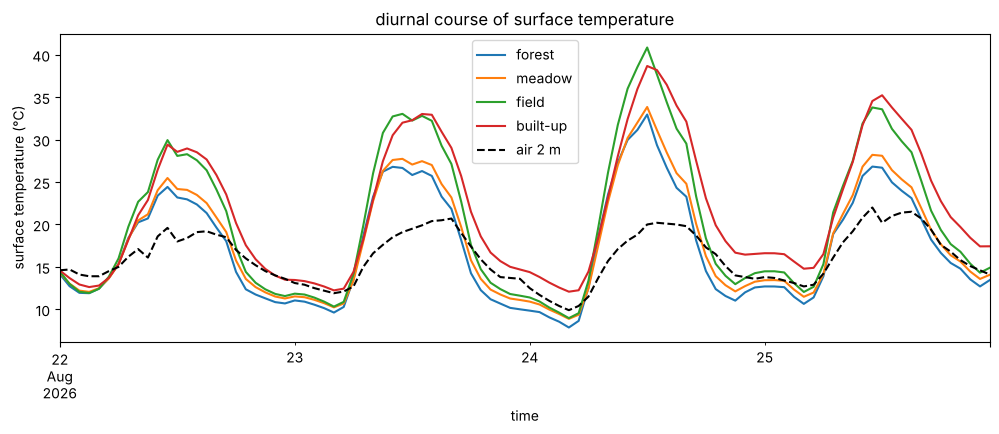

In [5]:
SURF = pd.DataFrame({                                             # ◀ parameter: surface properties (indicative)
    "albedo": albedo,
    "ε":      {"forest": 0.99, "meadow": 0.98, "field": 0.97, "built-up": 0.93},
    "β":      {"forest": 0.7, "meadow": 0.5, "field": 0.2, "built-up": 0.05},          # water availability for evaporation (0–1)
    "P":      {"forest": 800, "meadow": 1200, "field": 1000, "built-up": 2000},        # thermal inertia (J·m⁻²·K⁻¹·s⁻½)
})
WIND = 0.75                                  # ◀ parameter: wind near the surface as a fraction of the 10 m wind
TAU, LV, CP = 86400.0, 2.45e6, 1005.0

def q_sat(T, p):
    e = 6.112 * np.exp(17.62 * (T - 273.15) / (243.12 + T - 273.15))
    return 0.622 * e / p

def simulate(albedo, eps, beta, P, F=F, dt=60):
    """Force-restore model (Noilhan and Planton 1989): temperature of the surface Ts and of a deeper layer T2 under real weather."""
    CT = 2 * np.sqrt(np.pi / TAU) / P
    Ts = T2 = F.Ta.iloc[0]
    out = []
    for t, r in F.iterrows():
        h = 5.7 + 3.8 * r.wind_speed_10m * WIND
        for _ in range(int(3600 / dt)):
            Rn = (1 - albedo) * r.shortwave_radiation + eps * r.L_sky - eps * SIGMA * Ts ** 4
            H = h * (Ts - r.Ta)
            LE = beta * LV / CP * h * (q_sat(Ts, r.surface_pressure) - r.q_a)
            G = Rn - H - LE
            Ts, T2 = Ts + dt * (CT * G - 2 * np.pi / TAU * (Ts - T2)), T2 + dt * (Ts - T2) / TAU
        out.append({"time": t, "Ts": Ts - 273.15, "Rn": Rn, "H": H, "LE": LE, "G": G})
    return pd.DataFrame(out).set_index("time")

t0 = time.time()
runs = {name: simulate(s.albedo, s["ε"], s["β"], s.P) for name, s in SURF.iterrows()}
print(f"simulation of {len(runs)} surfaces in {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(12, 4))
for name, r in runs.items():
    r.Ts.plot(ax=ax, label=name)
F.temperature_2m.plot(ax=ax, color="k", ls="--", label="air 2 m")
ax.set(ylabel="surface temperature (°C)", title="diurnal course of surface temperature"); ax.legend(); plt.show()

> **✏️ Task 2.** Which surface is warmest at noon and which at night? Why is the built-up surface cooler than the field at noon although it hardly evaporates, and the warmest at night? At what time UTC does the surface reach its maximum, and why only after solar noon (in Prague around 11:00 UTC)?

*Your answer:* 

## 4. Where the energy goes during the day

In [6]:
day = F.index.normalize() == best
rows = {}
for name, r in runs.items():
    d = r[day]
    rows[name] = {"Rn (MJ/m²)": d.Rn.sum() * 3600 / 1e6, "H (MJ/m²)": d.H.sum() * 3600 / 1e6, "LE (MJ/m²)": d.LE.sum() * 3600 / 1e6,
                  "G (MJ/m²)": d.G.sum() * 3600 / 1e6, "Bowen ratio H/LE": d.H.sum() / d.LE.sum(),
                  "max Ts (°C)": d.Ts.max(), "hour of max (UTC)": d.Ts.idxmax().hour, "min Ts night (°C)": d.Ts.min()}
pd.DataFrame(rows).T.round(2)

,Rn (MJ/m²),H (MJ/m²),LE (MJ/m²),G (MJ/m²),Bowen ratio H/LE,max Ts (°C),hour of max (UTC),min Ts night (°C)
forest,12.30,1.58,10.13,0.59,0.16,32.96,12.0,7.86
meadow,11.57,2.45,8.17,0.96,0.30,33.85,12.0,8.88
field,10.87,4.80,4.92,1.15,0.97,40.86,12.0,8.97
built-up,10.30,6.46,1.36,2.48,4.74,38.68,12.0,12.08


> **✏️ Task 3.** What percentage of net radiation does the forest spend on evaporation and what percentage the built-up surface? What does the Bowen ratio tell you and why is it below 1 for the forest? Why is the daily sum of G positive, i.e. what happens to the heat in the ground during sunny days?

*Your answer:* 

## 5. Inertia and water

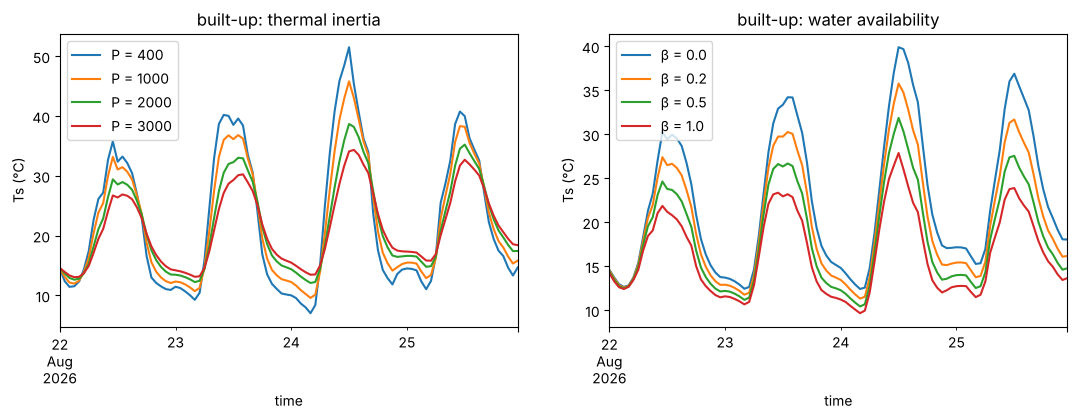

In [7]:
TEST = "built-up"                            # ◀ parameter: surface on which we try the properties
s = SURF.loc[TEST]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for P in [400, 1000, 2000, 3000]:
    simulate(s.albedo, s["ε"], s["β"], P).Ts.plot(ax=ax[0], label=f"P = {P}")
for beta in [0.0, 0.2, 0.5, 1.0]:
    simulate(s.albedo, s["ε"], beta, s.P).Ts.plot(ax=ax[1], label=f"β = {beta}")
ax[0].set(ylabel="Ts (°C)", title=f"{TEST}: thermal inertia"); ax[0].legend()
ax[1].set(ylabel="Ts (°C)", title=f"{TEST}: water availability"); ax[1].legend(); plt.show()

> **✏️ Task 4.** How do the diurnal temperature range and the time of the maximum change with increasing thermal inertia P? And with water availability β? Which of the two measures would help more against overheating streets during the day and which at night (greenery and watering, or different materials)?

*Your answer:* 

## 6. Comparison with the equilibrium from the basic version

In [8]:
from scipy.optimize import brentq
noon = runs["built-up"][day].Ts.idxmax()
r = F.loc[noon]
h = 5.7 + 3.8 * r.wind_speed_10m * WIND
cmp = {}
for name, s in SURF.iterrows():
    f = lambda T: (1 - s.albedo) * r.shortwave_radiation + s["ε"] * r.L_sky - s["ε"] * SIGMA * T ** 4 - h * (T - r.Ta)
    cmp[name] = {"equilibrium without evaporation and ground (°C)": brentq(f, 200, 400) - 273.15, "force-restore model (°C)": runs[name].Ts[noon]}
print(f"hour {noon} UTC, S = {r.shortwave_radiation:.0f} W/m², air {r.temperature_2m:.1f} °C")
pd.DataFrame(cmp).T.round(1)

hour 2026-08-24 12:00:00 UTC, S = 769 W/m², air 20.0 °C


,equilibrium without evaporation and ground (°C),force-restore model (°C)
forest,60.0,33.0
meadow,59.4,33.8
field,61.0,40.9
built-up,61.2,38.7


> **✏️ Task 5.** How many degrees higher is the equilibrium temperature without evaporation and ground heat flux than the model temperature? Which two terms of the balance explain the difference, and for which surface is which more important? Why does a drone thermal camera at noon show a difference between forest and field from which water stress can be inferred?

*Your answer:* 

> **✏️ Extension (optional).** Change `LAT, LON` to another place (for example a mountain station) or `N_DAYS` to 10 and look at how night minima change under clear and overcast skies. Why are frost hollows coldest on clear and calm nights?

*Your answer:* 

---
### Data sources and references

- Copernicus Sentinel-2 data 2024, ESA (L2A, Sen2Cor); AWS Open Data registry (`sentinel-cogs`), Earth Search catalogue (Element 84). Free use with attribution.
- Zanaga, D. et al. (2022). *ESA WorldCover 10 m 2021 v200*. https://doi.org/10.5281/zenodo.7254221 (CC BY 4.0).
- Weather: Open-Meteo.com (CC BY 4.0). https://open-meteo.com
- Liang, S. (2001). Narrowband to broadband conversions of land surface albedo I: Algorithms. *Remote Sensing of Environment* 76, 213–238. https://doi.org/10.1016/S0034-4257(00)00205-4
- Brutsaert, W. (1975). On a derivable formula for long-wave radiation from clear skies. *Water Resources Research* 11, 742–744. https://doi.org/10.1029/WR011i005p00742
- Crawford, T. M., Duchon, C. E. (1999). An improved parameterization for estimating effective atmospheric emissivity for use in calculating daytime downwelling longwave radiation. *Journal of Applied Meteorology* 38, 474–480.
- Noilhan, J., Planton, S. (1989). A simple parameterization of land surface processes for meteorological models. *Monthly Weather Review* 117, 536–549. https://doi.org/10.1175/1520-0493(1989)117<0536:ASPOLS>2.0.CO;2
- Oke, T. R., Mills, G., Christen, A., Voogt, J. A. (2017). *Urban Climates*. Cambridge University Press.

### How to cite

OpenSkyLab (2026). Where sunlight goes, advanced: the diurnal course of surface temperature [notebook, teaching resource], version 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/radiation_balance_pro_en.ipynb. Licence CC BY 4.0.

Notebook text and code: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data are under their providers' licences (see above).

*This resource was developed by the OpenSkyLab team with the assistance of the generative AI Claude (Anthropic), used for drafting code and text. The authors are responsible for the content.*